# Метод конфігураційної взаємодії (CI): як вийти за межі Хартрі–Фока (PySCF)

**Як працювати з цим ноутбуком.** Кожна частина має однакову будову: коротка теорія → приклад із кодом → завдання для самостійної роботи. Частини йдуть одна за одною, кожна спирається на попередню, тому не пропускайте.

**Мета роботи:**

1. Побачити, що дає метод Хартрі–Фока (HF): **зайняті** та **віртуальні** орбіталі.
2. Зрозуміти, як із цих орбіталей будуються **детермінанти** («конфігурації») і що таке **збудження**.
3. З'ясувати, чого HF «не бачить» (електронна кореляція) і чому це важливо.
4. Зрозуміти метод CI: хвильова функція — це **сума детермінантів**. Розв'язати найпростішу модель вручну.
5. Зрозуміти, що таке **FCI** — точний розв'язок у даному базисі — і навіщо він потрібен як еталон.
6. Перевірити **теорему Бріллюена**.
7. Побачити межі методу: усічений CI, розмірна узгодженість, розрив хімічного зв'язку.

> Попередня робота («Адіабатичне наближення») навчила будувати криву потенціальної енергії $U(R)$. Тут ми з'ясовуємо, наскільки точно вдається розв'язати **електронну задачу** при закріплених ядрах.

<a id="toc"></a>

### Зміст

Натисніть на назву, щоб перейти до розділу. У кожній частині є посилання «↑ до змісту».

* [Абетка (словничок термінів)](#glossary)
* [Частина 1. Що дає Хартрі–Фок: зайняті та віртуальні орбіталі](#part1)
    * [Завдання 1](#task1)
* [Частина 2. Чого не вміє HF: електронна кореляція](#part2)
    * [Завдання 2](#task2)
* [Частина 3. Ідея CI: хвильова функція — сума детермінантів](#part3)
    * [Завдання 3](#task3)
* [Частина 4. Загальний CI: матриця, усічення, CISD](#part4)
    * [Завдання 4](#task4)
* [Частина 5. Теорема Бріллюена](#part5)
    * [Завдання 5](#task5)
* [Частина 6. Ієрархія методів: H$_2$O і розтягування зв'язків](#part6)
    * [Завдання 6](#task6)
* [Частина 7. Розмірна неузгодженість усічених CI](#part7)
    * [Завдання 7](#task7)
* [Частина 8. Додаткові завдання для самостійної роботи](#part8)
* [Підсумок](#summary)

<a id="glossary"></a>
### Абетка для тих хто не знав і забув (повертайтесь сюди, якщо щось незрозуміло)

| Термін | Що це |
|---|---|
| **Базис** | набір готових функцій (центрованих на атомах), з яких ми будуємо все інше. Чим більший базис, тим точніше. Назви: `sto-3g` (мінімальний), `6-31g`, `cc-pvdz` (більші). |
| **Орбіталь** | функція, що описує **один** електрон: $\phi(\mathbf r)$. На одній орбіталі можуть сидіти до 2 електронів (↑ і ↓). |
| **Спін-орбіталь** | орбіталь + напрямок спіну (↑ або ↓). Одне «місце» для одного електрона. |
| **Зайнята / віртуальна орбіталь** | зайняту в HF заселено електронами; віртуальна — вільна («порожнє місце»). |
| **Детермінант (конфігурація)** | один певний спосіб розсадити електрони по спін-орбіталях (з урахуванням принципу Паулі). |
| **Збудження** | перенесення електрона із зайнятої орбіталі на віртуальну. Однократне (S), двократне (D), … |
| **Кореляція** | «обхід один одного»: електрони відчувають один одного миттєво, а не лише в середньому. |
| **FCI** | повний CI: усі можливі детермінанти в даному базисі. Це **точний** розв'язок у цьому базисі. |
| **Заморожений остов** | внутрішні орбіталі (наприклад, $1s$ кисню) не збуджуємо: вони майже не беруть участі в хімії, а розрахунок стає дешевшим. |
| **Ha, мГа** | одиниця енергії (гартрі): 1 Ha $=27.2$ еВ $=627.5$ ккал/моль; 1 мГа $=0.63$ ккал/моль. |

In [1]:
#!pip install pyscf # Розкоментуйте для встановлення PySCF

In [2]:
import math
from itertools import combinations
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from pyscf import gto, scf, fci, ci, cc, mp, ao2mo, tdscf

np.set_printoptions(precision=4, suppress=True)

HA2EV   = 27.211386      # Hartree -> eV
HA2KCAL = 627.5095       # Hartree -> ккал/моль

def rhf(atom, basis, spin=0, charge=0):
    # RHF-розрахунок; геометрія в ангстремах
    mol = gto.M(atom=atom, basis=basis, spin=spin, charge=charge, unit='Angstrom', verbose=0)
    return scf.RHF(mol).run()

def fci_energy(mf, frozen=0):
    # FCI-енергія в даному базисі; frozen — кількість заморожених (нижчих) орбіталей остова
    if frozen == 0:
        return fci.FCI(mf).kernel()[0]
    mol = mf.mol; C = mf.mo_coeff
    Cc, Ca = C[:, :frozen], C[:, frozen:]                    # остовні та активні орбіталі
    dm_c  = 2*Cc @ Cc.T                                      # густина заморожених електронів
    hcore = mf.get_hcore(); vhf = mf.get_veff(mol, dm_c)     # їхнє поле діє на решту електронів
    e_core = mol.energy_nuc() + np.einsum('ij,ji', hcore, dm_c) + 0.5*np.einsum('ij,ji', vhf, dm_c)
    h1  = Ca.T @ (hcore + vhf) @ Ca
    eri = ao2mo.kernel(mol, Ca)
    cs  = fci.direct_spin1.FCI(); cs.conv_tol = 1e-10
    e, _ = cs.kernel(h1, eri, Ca.shape[1], mol.nelectron - 2*frozen)
    return e + e_core

def water(scale, basis='6-31g'):
    # H2O: обидва зв'язки O–H = scale × рівноважний (0.9572 Å), кут H–O–H = 104.5°
    r0 = 0.9572*scale; th = np.radians(104.5/2)
    atom = f'O 0 0 0; H {r0*np.sin(th)} 0 {r0*np.cos(th)}; H {-r0*np.sin(th)} 0 {r0*np.cos(th)}'
    return gto.M(atom=atom, basis=basis, verbose=0)

<a id="part1"></a>
## Частина 1. Що дає Хартрі–Фок: зайняті та віртуальні орбіталі

[↑ до змісту](#toc)

### Що ми розв'язуємо

Є молекула з $N$ електронами, ядра стоять на місці. Треба знайти енергію й хвильову функцію електронів. Точно це вдається лише для найпростіших систем, тому для решти використовують наближення.

### Ідея Хартрі–Фока простими словами

1. Кожному електрону призначаємо **свою орбіталь** — функцію, що описує його рух.
2. Вважаємо, що електрон рухається в **усередненому** полі ядер і всіх інших електронів.
3. Орбіталі підбираємо так, щоб повна енергія була найменшою (самоузгоджений розрахунок, SCF).
4. Заселяємо орбіталі електронами: по два на орбіталь (↑ і ↓). Займаємо $N/2$ **найнижчих** орбіталей.

**Важливий факт.** Орбіталей HF знаходить стільки, скільки функцій у базисі, тобто $K$. Заселено лише $N/2$ найнижчих. Решта $K-N/2$ — це **віртуальні** (порожні) орбіталі. HF їх не використовує, але вони є, і саме з них потім будується CI.

### Приклад: молекула H$_2$ у мінімальному базисі

У мінімальному базисі в кожного атома H одна функція ($1s$), усього $K=2$. Тому буде 2 орбіталі: одна зайнята, одна віртуальна.

In [3]:
mol = gto.M(atom='H 0 0 0; H 0 0 0.74', basis='sto-3g', unit='Angstrom', verbose=0)
mf  = scf.RHF(mol).run()

print('Базисних функцій K          =', mol.nao)
print('Електронів N                =', mol.nelectron, '  → зайнятих орбіталей N/2 =', mol.nelectron//2)
print('Енергії орбіталей ε (Ha)    =', mf.mo_energy)
print('Заселеність (число електронів на орбіталі) =', mf.mo_occ)
print('\nКоефіцієнти орбіталей (рядки — атомні функції, стовпці — орбіталі):')
print(mf.mo_coeff)

Базисних функцій K          = 2
Електронів N                = 2   → зайнятих орбіталей N/2 = 1
Енергії орбіталей ε (Ha)    = [-0.5786  0.6711]
Заселеність (число електронів на орбіталі) = [2. 0.]

Коефіцієнти орбіталей (рядки — атомні функції, стовпці — орбіталі):
[[ 0.5488 -1.2125]
 [ 0.5488  1.2125]]


Дві орбіталі:

* **перша** ($\varepsilon=-0.58$ Ha, заселеність 2) — зайнята, коефіцієнти однакові: $\sigma_g\propto(1s_A+1s_B)$ — електрон «розмазаний» між атомами, зв'язувальна орбіталь;
* **друга** ($\varepsilon=+0.67$ Ha, заселеність 0) — віртуальна: $\sigma_u\propto(1s_A-1s_B)$, коефіцієнти різних знаків, між атомами є вузол — розпушувальна орбіталь.

**Висновок.** Віртуальна орбіталь — це такий самий «чесний» розв'язок рівнянь Фока, як і зайнята. Просто в HF на неї не посадили електронів. Нижче побачимо, що вона стає **доступною**, як тільки ми дозволимо електронам «переходити» на неї.

### Орбіталі більшої молекули: H$_2$O

Для H$_2$O у базисі `6-31g` маємо $K=13$ орбіталей, $N=10$ електронів. Скільки з них зайняті, скільки віртуальні?

In [4]:
atom_H2O = 'O 0 0 0.1173; H 0 0.7572 -0.4692; H 0 -0.7572 -0.4692'   # геометрія води, Å
mfw  = rhf(atom_H2O, '6-31g')
nocc = mfw.mol.nelectron // 2
K    = mfw.mo_coeff.shape[1]
print(f'орбіталей K = {K};  зайнятих = {nocc};  віртуальних = {K-nocc}')
print('енергії орбіталей, Ha:')
print('  зайняті    :', mfw.mo_energy[:nocc])
print('  віртуальні :', mfw.mo_energy[nocc:])

орбіталей K = 13;  зайнятих = 5;  віртуальних = 8
енергії орбіталей, Ha:
  зайняті    : [-20.5605  -1.3561  -0.7098  -0.5606  -0.5014]
  віртуальні : [0.2036 0.2997 1.0572 1.1644 1.1869 1.2157 1.3793 1.6962]


Зайняті орбіталі мають **від'ємну** енергію (електрони зв'язані), віртуальні — додатну або близьку до нуля. Між HOMO (найвища зайнята) та LUMO (найнижча віртуальна) є щілина.

### Спін-орбіталі і детермінант

Електрони — ферміони, тому їхня хвильова функція має змінювати знак при обміні двох електронів (принцип Паулі). Найпростіша функція з такою властивістю — **детермінант Слейтера**. Для двох електронів на орбіталі $\sigma_g$ зі спінами ↑ ($\alpha$) і ↓ ($\beta$):

$$\Phi_0=\frac1{\sqrt2}\begin{vmatrix}\sigma_g(1)\alpha(1)&\sigma_g(1)\beta(1)\\ \sigma_g(2)\alpha(2)&\sigma_g(2)\beta(2)\end{vmatrix}.$$

Якщо поміняти місцями електрони 1 і 2, рядки міняються й знак функції змінюється. Якщо посадити двох електронів на одну спін-орбіталь, два стовпці збігаються й детермінант дорівнює нулю — це і є принцип Паулі.

**Хартрі–Фок = ОДИН детермінант** $\Phi_0$, у якому зайняті $N/2$ нижчих орбіталей (по два електрони). Його називають *референсним* (опорним).

### Збудження: як з віртуальних орбіталей роблять нові детермінанти

Візьмемо $\Phi_0$ і **перенесемо електрон із зайнятої спін-орбіталі на віртуальну**. Отримаємо новий детермінант — іншу «конфігурацію»:

* **однократне збудження** (S): перенесли один електрон ($i\to a$), позначення $\Phi_i^a$;
* **двократне збудження** (D): перенесли два електрони ($ij\to ab$), $\Phi_{ij}^{ab}$;
* T, Q, … — три, чотири електрони.

Зробимо це наочно для H$_2$O (показано кілька орбіталей біля щілини HOMO–LUMO).

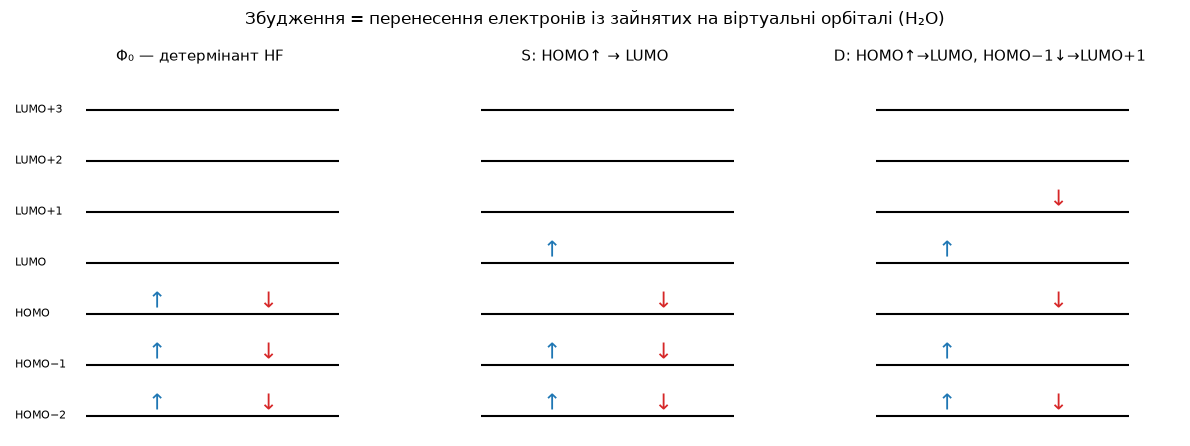

In [28]:
def draw_conf(ax, nlev, occ_a, occ_b, title):
    # одна конфігурація: рівні, ↑ (α) і ↓ (β) електрони
    for k in range(nlev):
        ax.hlines(k, 0, 1, color='k', lw=1.5)
        if k in occ_a: ax.text(0.28, k+0.12, '↑', fontsize=16, ha='center', color='tab:blue')
        if k in occ_b: ax.text(0.72, k+0.12, '↓', fontsize=16, ha='center', color='tab:red')
    ax.set_ylim(-0.4, nlev-0.2); ax.set_xlim(-0.3, 1.2); ax.set_title(title, fontsize=11); ax.axis('off')

# вікно з 7 орбіталей: 0,1,2 — три найвищі зайняті (2 = HOMO), 3,4,5,6 — перші віртуальні (3 = LUMO)
names = {0:'HOMO−2', 1:'HOMO−1', 2:'HOMO', 3:'LUMO', 4:'LUMO+1', 5:'LUMO+2', 6:'LUMO+3'}
fig, axs = plt.subplots(1, 3, figsize=(12, 4.5))
draw_conf(axs[0], 7, {0,1,2}, {0,1,2}, 'Φ₀ — детермінант HF')
draw_conf(axs[1], 7, {0,1,3}, {0,1,2}, 'S: HOMO↑ → LUMO')
draw_conf(axs[2], 7, {0,1,3}, {0,2,4}, 'D: HOMO↑→LUMO, HOMO−1↓→LUMO+1')
for k, n in names.items(): axs[0].text(-0.28, k, n, fontsize=8, va='center', ha='left')
plt.suptitle('Збудження = перенесення електронів із зайнятих на віртуальні орбіталі (H₂O)'); plt.tight_layout(); plt.show()

Кожна така картинка — **окремий детермінант**. Чим більше електронів перенесено, тим вищий «рівень збудження».

### Скільки детермінантів?

Спробуємо порахувати все явно. Спочатку для H$_2$ у мінімальному базисі: 2 просторові орбіталі $\Rightarrow$ 4 спін-орбіталі ($\sigma_g\uparrow,\sigma_g\downarrow,\sigma_u\uparrow,\sigma_u\downarrow$), 2 електрони. Усі способи вибрати 2 з 4:

In [29]:
so_names = ['σg↑', 'σg↓', 'σu↑', 'σu↓']                  # 0,1 — зайняті; 2,3 — віртуальні
print(f"{'детермінант':16s} {'рівень збудження':>17s} {'Ms (сума спінів)':>17s}")
for s in combinations(range(4), 2):
    level = sum(1 for i in s if i >= 2)                    # скільки електронів на віртуальних
    Ms    = sum(0.5 if i % 2 == 0 else -0.5 for i in s)
    kind  = {0: 'Φ0 (HF)', 1: 'S', 2: 'D'}[level]
    print(f"{' '.join(so_names[i] for i in s):16s} {kind:>17s} {Ms:+17.1f}")

детермінант       рівень збудження  Ms (сума спінів)
σg↑ σg↓                    Φ0 (HF)              +0.0
σg↑ σu↑                          S              +1.0
σg↑ σu↓                          S              +0.0
σg↓ σu↑                          S              +0.0
σg↓ σu↓                          S              -1.0
σu↑ σu↓                          D              +0.0


Усього $\binom42=6$ детермінантів: Φ$_0$ (HF), чотири однократні (S) і одне двократне (D) — це $\sigma_u^2$. Нас цікавлять стани з нульовим сумарним спіном $M_s=0$, їх 4. Потім симетрія залишить усього **дві** суттєві конфігурації: $\sigma_g^2$ і $\sigma_u^2$ — до цього повернемось в частині 4.

Тепер для H$_2$O: порахуємо детермінанти за рівнем збудження. Правило: рівень збудження дорівнює числу електронів на віртуальних орбіталях. Для $\alpha$ і $\beta$ електронів рахуємо окремо й множимо.

In [30]:
def count_by_level(K, nocc):
    # кількість детермінантів кожного рівня збудження (nocc α- і nocc β-електронів на K орбіталях)
    strings = list(combinations(range(K), nocc))
    lev = Counter(sum(1 for p in s if p >= nocc) for s in strings)     # для одного спіну
    total = Counter()
    for la, na in lev.items():
        for lb, nb in lev.items():
            total[la + lb] += na * nb
    return dict(sorted(total.items()))

for basis, K in [('sto-3g', 7), ('6-31g', 13)]:
    cnt = count_by_level(K, 5)
    tot = sum(cnt.values())
    cisd = cnt.get(0,0) + cnt.get(1,0) + cnt.get(2,0)
    print(f'H2O/{basis}:  K={K},  всього детермінантів (FCI) = {tot:,}')
    print('   за рівнем збудження:', cnt)
    print(f'   у CISD (рівні 0,1,2): {cisd:,}  — {100*cisd/tot:.2f}% від усіх\n')

H2O/sto-3g:  K=7,  всього детермінантів (FCI) = 441
   за рівнем збудження: {0: 1, 1: 20, 2: 120, 3: 200, 4: 100}
   у CISD (рівні 0,1,2): 141  — 31.97% від усіх

H2O/6-31g:  K=13,  всього детермінантів (FCI) = 1,656,369
   за рівнем збудження: {0: 1, 1: 80, 2: 2160, 3: 23520, 4: 123900, 5: 341712, 6: 514080, 7: 423360, 8: 185220, 9: 39200, 10: 3136}
   у CISD (рівні 0,1,2): 2,241  — 0.14% від усіх



Бачимо:

* детермінантів швидко стає **дуже багато**;
* найбільше — високих збуджень (T, Q, …), але вони, як побачимо, мають малі коефіцієнти;
* якщо залишити тільки рівні 0, 1, 2 (так званий **CISD**), детермінантів на порядки менше.

<a id="task1"></a>
### Завдання 1

**(а)** Для HeH$^+$ (`atom='He 0 0 0; H 0 0 0.8'`, `charge=1`, базис `6-31g`) визначте: скільки орбіталей $K$, скільки зайнятих, скільки віртуальних? Яка щілина HOMO–LUMO?

**(б)** Скільки детермінантів кожного рівня збудження в FCI для H$_2$ у `6-31g` ($K=4$, $N=2$)? Скільки з них в CISD? Перевірте, що сума збігається з $\binom{K}{1}^2$.

**(в)** Чому кількість двократних збуджень для H$_2$O/`6-31g` набагато більша за однократних? (Підказка: порахуйте, скількома способами вибрати 2 електрони й 2 віртуальні орбіталі.)

In [31]:
# Ваш код тут

<a id="part2"></a>
## Частина 2. Чого не вміє HF: електронна кореляція

[↑ до змісту](#toc)

### Що HF бачить, а що ні

У HF кожен електрон відчуває лише **середнє розмазане поле** решти. Насправді електрони відчувають один одного **миттєво**: якщо один тут, інший «відскакує» подалі. Цей рух «в обхід» називають **електронною кореляцією**. HF його не описує, тому **енергія HF завжди вища за точну**.

**Кореляційна енергія:**

$$E_{corr}=E_{\text{точна}}-E_{HF}<0 .$$

(Обидві енергії треба брати в **одному й тому самому базисі**. Тоді точна — це FCI: $E_{corr}=E_{FCI}-E_{HF}$.)

*Примітка.* Електрони з однаковим спіном уникають одне одного ще й через принцип Паулі. Це (обмінна кореляція) HF враховує правильно. Тож «кореляція» у цій роботі — це вплив кулонівського відштовхування.

### Два види кореляції

| | Динамічна | Статична |
|---|---|---|
| Суть | електрони постійно трохи «ухиляються» одне від одного | є **кілька майже рівноцінних** способів розсадити електрони; HF вибирає один і помиляється принципово |
| У CI-розкладі | дуже багато детермінантів, кожен з **малим** внеском; вага $c_0^2\approx1$ | **декілька** детермінантів зі значною вагою |
| Приклади | майже всі молекули біля рівноваги | розрив зв'язку, бірадикали, атом Be |
| HF як наближення | добре | якісно хибне |

Практична діагностика: **вага HF-детермінанта $c_0^2$**. Якщо вона близька до 1 — кореляція динамічна; якщо помітно менша (наприклад, $<0.9$) — є статична.

### Приклад: скільки кореляції?

Порахуємо $E_{corr}$ для кількох систем: HF проти FCI.

In [32]:
systems = [('He',   'He 0 0 0',             'cc-pvdz', 0),
           ('Be',   'Be 0 0 0',             'cc-pvdz', 0),
           ('H2',   'H 0 0 0; H 0 0 0.74',  'cc-pvdz', 0),
           ('LiH',  'Li 0 0 0; H 0 0 1.595','cc-pvdz', 0),
           ('H2O',  atom_H2O,               '6-31g',   1)]     # H2O: заморожено 1s-остов
print(f"{'система':8s} {'пар e⁻':>6s} {'E_corr, мГа':>12s} {'еВ':>7s} {'еВ/пару':>8s}")
for name, atom, basis, fz in systems:
    m  = rhf(atom, basis)
    ec = fci_energy(m, frozen=fz) - m.e_tot
    npairs = (m.mol.nelectron - 2*fz)//2
    print(f'{name:8s} {npairs:6d} {ec*1000:12.2f} {ec*HA2EV:7.2f} {ec*HA2EV/npairs:8.2f}')

система  пар e⁻  E_corr, мГа      еВ  еВ/пару
He            1       -32.43   -0.88    -0.88
Be            2       -45.07   -1.23    -0.61
H2            1       -34.67   -0.94    -0.94
LiH           2       -31.11   -0.85    -0.42
H2O           4      -135.98   -3.70    -0.93


Кореляційна енергія — це приблизно **0.4–0.9 еВ на кожну електронну пару**. Здається мало, але «хімічна точність» (потрібна для передбачення реакцій) — це 1 ккал/моль $=1.6$ мГа. Тобто $E_{corr}$ у **десятки і сотні разів більша** за потрібну нам точність, і ігнорувати її не можна.

<a id="task2"></a>
### Завдання 2

**(а)** Додайте до таблиці молекулу N$_2$ у `6-31g` (відстань 1.1 Å, `frozen=2`, FCI дуже довгий — скористайтесь **CCSD(T)** (`cc.CCSD(mf)`, `ccsd_t()`) і порівняйте $E_{corr}$ в розрахунку на пару електронів).

**(б)** Скільки відсотків повної енергії електронів становить $E_{corr}$ для H$_2$O (`6-31g`)? Порівняйте з «хімічною точністю».

In [33]:
# Ваш код тут

<a id="part3"></a>
## Частина 3. Ідея CI: хвильова функція — сума детермінантів

[↑ до змісту](#toc)

### Головна ідея

Детермінанти з частини 1 (HF, S, D, T, …) утворюють **повний набір**: будь-яку антисиметричну функцію електронів у даному базисі можна записати як їхню лінійну комбінацію. Це схоже на розклад звичайної функції в ряд Фур'є. Тому точну функцію пишемо як:

$$\Psi=c_0\,\Phi_0+\sum c_S\,\Phi_S+\sum c_D\,\Phi_D+\sum c_T\,\Phi_T+\dots$$

* $c_I$ — **коефіцієнти** (числа), $c_I^2$ — **ваги** конфігурацій; сума ваг дорівнює 1;
* HF — це окремий випадок: лише $c_0=1$;
* Метод CI — це спосіб **знайти** коефіцієнти $c_I$ (і енергію) для обраного набору детермінантів.

Подивимось на справжні коефіцієнти для H$_2$ (мінімальний базис, FCI). Тут лише дві суттєві конфігурації: $\sigma_g^2$ (це $\Phi_0$) та $\sigma_u^2$ (двократне збудження).

In [34]:
for R in [0.74, 3.0]:
    m = rhf(f'H 0 0 0; H 0 0 {R}', 'sto-3g')
    e, civ = fci.FCI(m).kernel()
    print(f'R = {R:4.2f} Å:  c(σg²) = {civ[0,0]:+.4f}  (вага {civ[0,0]**2:.3f}),   c(σu²) = {civ[1,1]:+.4f}  (вага {civ[1,1]**2:.3f})')

R = 0.74 Å:  c(σg²) = +0.9936  (вага 0.987),   c(σu²) = -0.1125  (вага 0.013)
R = 3.00 Å:  c(σg²) = +0.7331  (вага 0.537),   c(σu²) = -0.6801  (вага 0.463)


**Дивіться, що відбувається:**

* біля рівноваги ($R=0.74$ Å) HF-детермінант має вагу 0.987 — майже вся функція. Це **динамічна** кореляція, HF добре працює;
* при $R=3$ Å вага $\sigma_g^2$ впала до 0.54, а $\sigma_u^2$ зросла до 0.46 — **обидві** конфігурації вагомі. Це **статична** кореляція: HF з одним детермінантом тут принципово недостатній.

### Модель, яку можна розв'язати вручну: H$_2$ (дві конфігурації)

Базис $\{\Phi_0,\Phi_D\}$ ($\Phi_0=\sigma_g^2$, $\Phi_D=\sigma_u^2$). Тоді $\mathbf H$ — матриця $2\times2$:

$$\mathbf H=\begin{pmatrix}E_0&K\\K&E_D\end{pmatrix},\qquad
E_0=\langle\Phi_0|\hat H|\Phi_0\rangle=E_{HF},\quad E_D=\langle\Phi_D|\hat H|\Phi_D\rangle,\quad K=\langle\Phi_0|\hat H|\Phi_D\rangle .$$

* $E_0$ — енергія HF-детермінанта, $E_D$ — енергія двократно збудженого;
* $K>0$ — «зв'язок» між ними (чому він ненульовий: $\hat H$ містить кулонівське відштовхування двох електронів, яке і може «переселити» обидва електрони з $\sigma_g$ на $\sigma_u$).

Розв'язок задачі на власні значення $\mathbf H\mathbf c=E\mathbf c$ ($\Delta=(E_D-E_0)/2$):

$$E=\frac{E_0+E_D}2-\sqrt{\Delta^2+K^2},\qquad E_{corr}=E-E_0=\Delta-\sqrt{\Delta^2+K^2}.$$

* Якщо $K\ll\Delta$: $E_{corr}\approx-\dfrac{K^2}{E_D-E_0}$ (звичайна теорія збурень 2-го порядку);
* Якщо $\Delta\to0$ (орбіталі $\sigma_g$ і $\sigma_u$ майже виродженi, як при розриві зв'язку), збурення **не мале**, і $\Psi\to(\Phi_0-\Phi_D)/\sqrt2$: обидві конфігурації мають вагу $\tfrac12$.

**Фізика розриву зв'язку.** Один $\sigma_g^2$ дає 50% іонних структур H$^+$H$^-$ (електрон — біля одного з атомів), навіть при $R\to\infty$, що неправильно: на безкінечності мають бути два нейтральні атоми. Додавання $\sigma_u^2$ з коефіцієнтом $-1/\sqrt2$ **гасить іонну частину** й залишає лише нейтральні структури. (Якщо хочете, розкладіть $\sigma_g=(A+B)/\sqrt2$, $\sigma_u=(A-B)/\sqrt2$ в атомні орбіталі й переконайтеся.)

Реалізуємо модель: порахуємо $E_0$, $E_D$, $K$ з інтегралів і порівняємо з FCI.

In [35]:
def h2_model(R, basis='sto-3g'):
    # 2x2 CI для H2: повертає (E0, E_D, K, E_CI, c0, c_D, mf)
    mol = gto.M(atom=f'H 0 0 0; H 0 0 {R}', basis=basis, unit='Angstrom', verbose=0)
    mf  = scf.RHF(mol).run()
    Cg  = mf.mo_coeff[:, :2]                                   # σg, σu
    h   = Cg.T @ mf.get_hcore() @ Cg                           # одноелектронні інтеграли
    g   = ao2mo.restore(1, ao2mo.kernel(mol, Cg), 2)           # двоелектронні інтеграли (pq|rs)
    Vnn = mol.energy_nuc()
    E0  = 2*h[0, 0] + g[0, 0, 0, 0] + Vnn                      # σg²
    ED  = 2*h[1, 1] + g[1, 1, 1, 1] + Vnn                      # σu²
    K   = g[0, 1, 0, 1]
    w, vec = np.linalg.eigh(np.array([[E0, K], [K, ED]]))
    vec = vec[:, 0] * np.sign(vec[0, 0])                       # домовленість: c0 > 0
    return E0, ED, K, w[0], vec[0], vec[1], mf

print(f"{'R, Å':>5s} {'E_HF':>11s} {'E_2x2':>11s} {'E_FCI':>11s} {'різниця':>10s} {'c0':>7s} {'c_D':>7s}")
for R in [0.5, 0.74, 1.5, 3.0]:
    E0, ED, K, E2, c0_, cD_, m = h2_model(R)
    print(f'{R:5.2f} {E0:11.6f} {E2:11.6f} {fci_energy(m):11.6f} {E2-fci_energy(m):10.1e} {c0_:7.4f} {cD_:7.4f}')

 R, Å        E_HF       E_2x2       E_FCI    різниця      c0     c_D
 0.50   -1.042996   -1.055160   -1.055160    1.3e-15  0.9974 -0.0718
 0.74   -1.116759   -1.137284   -1.137284    4.4e-16  0.9936 -0.1125
 1.50   -0.910874   -0.998149   -0.998149    0.0e+00  0.9347 -0.3554
 3.00   -0.656048   -0.933632   -0.933632   -2.2e-16  0.7331 -0.6801


Матриця $2\times2$ збігається з FCI до машинної точності. У мінімальному базисі FCI — це і є ця матриця. Тепер побудуємо криву $U(R)$ і подивимось на ваги.

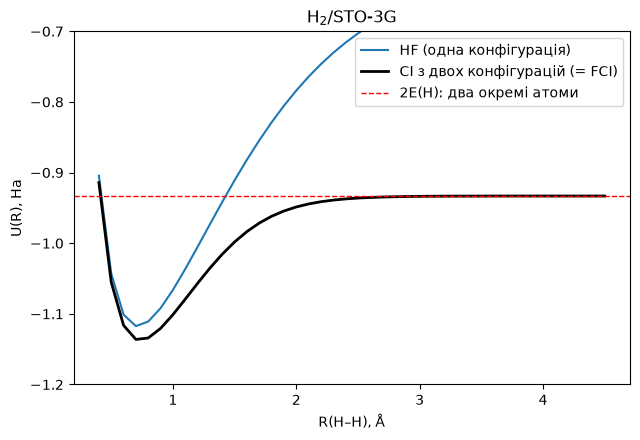

Ваги конфігурацій у CI-функції:
 R, Å   вага σg² (HF)   вага σu²
 0.50           0.995      0.005
 0.74           0.987      0.013
 1.00           0.969      0.031
 1.50           0.874      0.126
 2.00           0.712      0.288
 3.00           0.537      0.463
 4.50           0.501      0.499


In [36]:
Rs  = np.linspace(0.4, 4.5, 42)
res = np.array([h2_model(R)[:6] for R in Rs])          # E0, ED, K, E_CI, c0, cD
E_hf, E_ci = res[:, 0], res[:, 3]
E_atom = 2*scf.UHF(gto.M(atom='H', basis='sto-3g', spin=1, verbose=0)).run().e_tot   # 2E(H): два окремі атоми

plt.figure(figsize=(6.5, 4.5))
plt.plot(Rs, E_hf, label='HF (одна конфігурація)')
plt.plot(Rs, E_ci, 'k', lw=2, label='CI з двох конфігурацій (= FCI)')
plt.axhline(E_atom, color='r', ls='--', lw=1, label='2E(H): два окремі атоми')
plt.ylim(-1.2, -0.7); plt.xlabel('R(H–H), Å'); plt.ylabel('U(R), Ha')
plt.title('H$_2$/STO-3G'); plt.legend(); plt.tight_layout(); plt.show()

print('Ваги конфігурацій у CI-функції:')
print(f"{'R, Å':>5s} {'вага σg² (HF)':>15s} {'вага σu²':>10s}")
for R in [0.5, 0.74, 1.0, 1.5, 2.0, 3.0, 4.5]:
    c0_, cD_ = h2_model(R)[4:6]
    print(f'{R:5.2f} {c0_**2:15.3f} {cD_**2:10.3f}')

**Що видно:**

* **HF** (одна конфігурація $\sigma_g^2$) при розтягуванні **не виходить** на межу $2E(\mathrm H)$ (червона лінія): це якраз 50% іонних структур H$^+$H$^-$, про які ми говорили;
* **CI з двох конфігурацій** виходить на правильну межу;
* у таблиці ваг: біля рівноваги ($R=0.74$ Å) майже все — HF-конфігурація (динамічна кореляція); при великих $R$ обидві ваги вирівнюються до $\tfrac12$ — це і є **статична кореляція**.

<a id="task3"></a>
### Завдання 3

**(а) CI для двох електронів «з нуля».** Для двох електронів у $K$ орбіталях основний синглетний стан шукають як $\Psi=\sum_{pq}C_{pq}\,\phi_p(\mathbf r_1)\phi_q(\mathbf r_2)$, а енергія — найнижче власне значення матриці розміру $K^2\times K^2$:

$$H_{pq,rs}=h_{pr}\delta_{qs}+\delta_{pr}h_{qs}+(pr|qs),\qquad E=E_{el}+V_{NN}.$$

Тут $h_{pr}$ — одноелектронні, $(pr|qs)$ — двоелектронні інтеграли в базисі орбіталей. Візьміть їх так само, як у функції `h2_model` (`mf.get_hcore()`, `ao2mo`), але для **всіх** $K$ орбіталей, для H$_2$ у `cc-pvdz`. Діагоналізуйте (`np.linalg.eigvalsh`) і порівняйте з `fci_energy(mf)`: збіг має бути $\sim10^{-10}$ Ha.

**(б)** Побудуйте $U(R)$ для H$_2$/`cc-pvdz` двома методами (HF і FCI) і знайдіть $D_e=2E(\mathrm H)-U_{min}$. Скільки відсотків $D_e$ втрачає HF? (Порівняйте з роботою про адіабатичне наближення.)

**(в)** Складіть таблицю ваг $c_0^2$ і $c_D^2$ для $R=0.5,\ 1,\ 1.5,\ 2,\ 3,\ 4$ Å (функція `h2_model`). При якому приблизно $R$ вага двократного збудження $\sigma_u^2$ перевищує 10%?

In [37]:
# Ваш код тут

<a id="part4"></a>
## Частина 4. Загальний CI: матриця, усічення, CISD

[↑ до змісту](#toc)

### Матриця CI

Для довільної молекули повторюємо те саме, що й у моделі $2\times2$, але детермінантів тепер багато. Вибираємо набір $\{\Phi_I\}$ і шукаємо найнижчий розв'язок задачі на власні значення:

$$\mathbf H\mathbf c=E\,\mathbf c,\qquad H_{IJ}=\langle\Phi_I|\hat H|\Phi_J\rangle .$$

* Найнижче власне значення — основний стан. Він завжди **вищий** за точну енергію, тобто це верхня межа (варіаційний принцип).
* Інші власні значення — **збуджені стани** молекули. CI дає їх «безкоштовно».

**Багато елементів матриці — нулі.** Оператор $\hat H$ складається з одно- та двоелектронних доданків, тому він «з'єднує» лише ті детермінанти, що відрізняються **не більше ніж двома** орбіталями (правило Слейтера–Кондона). Тому між Φ$_0$ і трикратними збудженнями — нуль. Структура матриці за рівнями збудження (✓ — можливо, не нуль):

| | Φ$_0$ | S | D | T | Q |
|---|:-:|:-:|:-:|:-:|:-:|
| Φ$_0$ | $E_{HF}$ | **0** (див. частину 5) | ✓ | 0 | 0 |
| S | **0** | ✓ | ✓ | ✓ | 0 |
| D | ✓ | ✓ | ✓ | ✓ | ✓ |
| T | 0 | ✓ | ✓ | ✓ | ✓ |
| Q | 0 | 0 | ✓ | ✓ | ✓ |

### Усічений CI: назви

Беремо не всі детермінанти, а лише до певного рівня збудження:

| Назва | Що входить | Для чого |
|---|---|---|
| CIS | Φ$_0$ + S | збуджені стани (основний стан не покращується!) |
| CISD | Φ$_0$ + S + D | основний стан; найпоширеніший |
| CISDT, CISDTQ | + T, + Q | точніше, але дорожче |
| **FCI** | усі | точний розв'язок у даному базисі |

### FCI: точний розв'язок у даному базисі

Якщо взяти в розклад **усі** детермінанти (усі рівні збудження: S, D, T, … аж до $N$-кратних), отримаємо **повний CI — FCI** (Full CI).

* У FCI ми не відкидаємо **жодного** способу розсадити електрони по орбіталях. Тому це **точний** розв'язок задачі в обраному базисі. Єдина похибка — що сам базис скінченний.
* $E_{FCI}$ — найнижча енергія, яку взагалі можна отримати в даному базисі. Будь-який усічений CI дає $E\ge E_{FCI}$.
* Тому FCI — це **еталон**: з ним порівнюють наближені методи, і саме він дає кореляційну енергію $E_{corr}=E_{FCI}-E_{HF}$ (частина 2).
* Ціна — кількість детермінантів швидко зростає, тому FCI можливий лише для малих систем (таблиця нижче).

У PySCF: `e, civec = fci.FCI(mf).kernel()`. Тут `e` — повна енергія $E_{FCI}$, а `civec` — таблиця коефіцієнтів $c_I$: рядки відповідають розміщенню α-електронів, стовпці — β-електронів.

Подивимось на H$_2$O у `sto-3g` (441 детермінант, ми їх рахували в частині 1). Знайдемо **сумарну вагу** $\sum c_I^2$ кожного рівня збудження й порівняємо з кількістю детермінантів на цьому рівні. Зробимо це для рівноважної та розтягнутої ($s=2$) геометрії.

In [38]:
for s in [1.0, 2.0]:
    mfs = scf.RHF(water(s, 'sto-3g')).run()
    cs  = fci.FCI(mfs); e_fci, civ = cs.kernel()
    nocc_s = 5
    strs = fci.cistring.make_strings(range(cs.norb), cs.nelec[0])         # α-рядки (біт = зайнята орбіталь)
    lev  = np.array([bin(int(x) >> nocc_s).count('1') for x in strs])     # скільки електронів на віртуальних орбіталях
    n_det = count_by_level(cs.norb, nocc_s)
    weight = {l: sum((civ[np.ix_(lev == la, lev == lb)]**2).sum()
                     for la in set(lev) for lb in set(lev) if la + lb == l) for l in range(5)}
    e_cisd = ci.CISD(mfs).run().e_tot
    print(f's = {s}:  E_HF = {mfs.e_tot:.5f},  E_CISD = {e_cisd:.5f},  E_FCI = {e_fci:.5f} Ha;  сума ваг = {sum(weight.values()):.6f}')
    print(f"   {'рівень':>8s} {'детермінантів':>14s} {'вага':>10s}")
    for l, name in enumerate(['HF', 'S', 'D', 'T', 'Q']):
        print(f'   {name:>8s} {n_det[l]:14d} {weight[l]:10.5f}')
    print()

s = 1.0:  E_HF = -74.96293,  E_CISD = -75.01171,  E_FCI = -75.01241 Ha;  сума ваг = 1.000000
     рівень  детермінантів       вага
         HF              1    0.97362
          S             20    0.00033
          D            120    0.02584
          T            200    0.00003
          Q            100    0.00017

s = 2.0:  E_HF = -74.44578,  E_CISD = -74.71747,  E_FCI = -74.77192 Ha;  сума ваг = 1.000000
     рівень  детермінантів       вага
         HF              1    0.52478
          S             20    0.00552
          D            120    0.40894
          T            200    0.00160
          Q            100    0.05916



**Що видно:**

* сума ваг дорівнює 1 (функція нормована);
* детермінантів на кожному рівні багато (S: 20, D: 120, T: 200, Q: 100), але біля рівноваги вагомі лише HF і D, а ваги S, T, Q менші за $0.001$. Саме тому усічення на D (CISD) працює;
* найбільший внесок після HF дають двократні збудження (D), однократні (S) майже нічого не дають (чому — див. частину 5);
* при розтягуванні вага HF падає майже вдвічі, а **чотирикратні збудження зростають приблизно до 6%**. CISD їх не має, і саме тому його точність псується (частини 6–7).

### Вартість: FCI проти CISD

Порівняйте, скільки детермінантів у FCI і скільки елементів у CISD для H$_2$O у різних базисах.

In [39]:
print(f"{'базис':9s} {'K':>4s} {'det(FCI)':>12s} {'розмір CISD':>13s}")
for basis in ['sto-3g', '6-31g', 'cc-pvdz', 'cc-pvtz']:
    K = gto.M(atom=atom_H2O, basis=basis, verbose=0).nao
    o = 5; v = K - o
    n_fci  = math.comb(K, o)**2                 # C(K,5)·C(K,5): α- і β-електрони розсаджуємо незалежно
    n_cisd = 1 + o*v + (o*v)**2                 # розмір вектора CISD у PySCF (замкнена оболонка)
    print(f'{basis:9s} {K:4d} {n_fci:12.3e} {n_cisd:13.3e}')

базис        K     det(FCI)   розмір CISD
sto-3g       7    4.410e+02     1.110e+02
6-31g       13    1.656e+06     1.641e+03
cc-pvdz     24    1.807e+09     9.121e+03
cc-pvtz     58    2.100e+13     7.049e+04


FCI для H$_2$O у `cc-pVDZ` — це $10^9$ детермінантів, у `cc-pVTZ` — $10^{13}$. CISD зростає лише поліноміально. Але тоді виникає питання: **яку ціну ми платимо**, відкидаючи T, Q, …? Дізнаємось у частинах 6–7.

### CISD для H$_2$O

Запустимо CISD у PySCF і подивимось на ваги конфігурацій.

In [40]:
mf   = rhf(atom_H2O, '6-31g')
myci = ci.CISD(mf).run()
c0, c1, c2 = myci.cisdvec_to_amplitudes(myci.ci)       # коефіцієнти: HF, однократні, двократні
nmo_, nocc_ = myci.nmo, myci.nocc

def weight(c0_, c1_, c2_):
    # вага частини вектора CISD (норма RCISD-вектора в PySCF: 2 v·v − c0² − Σ c2[j,i,a,b]c2[i,j,a,b])
    v = myci.amplitudes_to_cisdvec(c0_, c1_, c2_)
    return ci.cisd.dot(v, v, nmo_, nocc_)

z1, z2 = np.zeros_like(c1), np.zeros_like(c2)
W0, WS, WD = weight(c0, z1, z2), weight(0, c1, z2), weight(0, z1, c2)
print(f'вага HF c0² = {W0:.4f};   однократні S: {WS:.4f};   двократні D: {WD:.4f};   сума = {W0+WS+WD:.4f}')
print(f'E_corr(CISD) = {myci.e_corr*1000:.2f} мГа;  E_HF = {mf.e_tot:.6f}, E_CISD = {myci.e_tot:.6f} Ha')

вага HF c0² = 0.9606;   однократні S: 0.0005;   двократні D: 0.0389;   сума = 1.0000
E_corr(CISD) = -130.11 мГа;  E_HF = -75.983974, E_CISD = -76.114086 Ha


Вага HF-детермінанта $\approx0.96$: це типова **динамічна** кореляція. Двократних збуджень значно більше за однократні.

### Хто дає кореляційну енергію?

Спроєктуємо рівняння $\hat H\Psi=E\Psi$ на $\Phi_0$ (з нормуванням $c_0=1$). Оскільки $\Phi_0$ з'єднується лише з S і D (таблиця вище), отримаємо:

$$E_{corr}=\sum_{ia}c_i^a\,\langle\Phi_0|\hat H|\Phi_i^a\rangle+\sum_{i<j,\ a<b}c_{ij}^{ab}\,\langle ij||ab\rangle .$$

Перший доданок дорівнює нулю (теорема Бріллюена, частина 5), тому **енергію дають лише двократні збудження**:

$$E_{corr}=\sum_{i<j,\ a<b}c_{ij}^{ab}\,\langle ij||ab\rangle\qquad\Big(\text{для замкненої оболонки: }\sum_{ijab}(2c_{ij}^{ab}-c_{ij}^{ba})(ia|jb)\Big).$$

Це точно, але **не означає**, що S, T, Q не потрібні: коефіцієнти $c_{ij}^{ab}$ знаходяться з усієї матриці (D «чує» S, T, Q через ненульові блоки). Перевіримо формулу:

In [41]:
eris = myci.ao2mo()
t2   = c2 / c0                                         # проміжне нормування c0 = 1
E_D  = 2*np.einsum('ijab,iajb', t2, eris.ovov) - np.einsum('ijab,ibja', t2, eris.ovov)
print(f'E_corr (PySCF, CISD)             = {myci.e_corr:.8f} Ha')
print(f'E_corr за формулою (лише D)       = {E_D:.8f} Ha')

E_corr (PySCF, CISD)             = -0.13011203 Ha
E_corr за формулою (лише D)       = -0.13011203 Ha


### Приклад статичної кореляції в атомі: Be

Для атома Be рівні $2s$ і $2p$ відносно близькі (збудження $2s\to2p$ коштує лише ~3–5 еВ). Тому конфігурація $2p^2$ значно домішується до $2s^2$. Подивимось на FCI-розклад (орбіталі за енергією: 0 — $1s$, 1 — $2s$, 2–4 — $2p$).

In [42]:
mfBe = rhf('Be 0 0 0', 'cc-pvdz')
cs = fci.FCI(mfBe); eBe, civ = cs.kernel()
print('E_corr(FCI) = %.2f мГа' % ((eBe - mfBe.e_tot)*1000))

lc = fci.addons.large_ci(civ, cs.norb, cs.nelec, tol=0.02, return_strs=False)
lc = sorted(lc, key=lambda x: -abs(x[0]))[:6]
print('\nнайважливіші детермінанти:')
for cI, ia, ib in lc:
    print(f'  c = {cI:+.4f}   вага = {cI**2:.4f}    α-орбіталі {[int(x) for x in ia]}  β-орбіталі {[int(x) for x in ib]}')

W_2p2 = sum(cI**2 for cI, ia, ib in lc if list(ia) == list(ib) and list(ia)[1] in (2, 3, 4))
print(f'\nвага конфігурацій 1s² 2p² (три орієнтації): {W_2p2:.3f}')

E_corr(FCI) = -45.07 мГа

найважливіші детермінанти:
  c = +0.9524   вага = 0.9070    α-орбіталі [0, 1]  β-орбіталі [0, 1]
  c = -0.1423   вага = 0.0203    α-орбіталі [0, 4]  β-орбіталі [0, 4]
  c = -0.1423   вага = 0.0203    α-орбіталі [0, 2]  β-орбіталі [0, 2]
  c = -0.1423   вага = 0.0203    α-орбіталі [0, 3]  β-орбіталі [0, 3]
  c = -0.0646   вага = 0.0042    α-орбіталі [0, 7]  β-орбіталі [0, 3]
  c = -0.0646   вага = 0.0042    α-орбіталі [0, 3]  β-орбіталі [0, 7]

вага конфігурацій 1s² 2p² (три орієнтації): 0.061


Конфігурації $1s^22p^2$ (три орієнтації) мають сумарну вагу ~6% — це не «дрібна» поправка, а помітна **статична** кореляція: одного детермінанта $1s^22s^2$ недостатньо. (Як систематично враховувати такі випадки — тема наступної роботи.)

<a id="task4"></a>
### Завдання 4

**(а)** Для H$_2$O (`6-31g`) розтягуйте **обидва** зв'язки O–H у $s=0.8,\ 1.0,\ 1.5,\ 2.0$ разів від рівноважної (кут $104.5^\circ$; використайте готову функцію `water(s, '6-31g')` з початку ноутбука). Побудуйте $c_0^2$ від $s$. Що це говорить про вид кореляції при розтягуванні?

**(б)** Порівняйте $c_0^2$ для H$_2$ (`cc-pvdz`) при $R=0.74$ і $R=3$ Å та для N$_2$ (`cc-pvdz`, `myci.frozen=2`) при $R=1.1$ і $2.5$ Å. У якій системі HF гірше працює при розтягуванні й чому? (Підказка: скільки електронних пар розривається.)

**(в)** Для Be порахуйте $c_0^2$ у CISD. Скільки відсотків $E_{corr}$ відновлює CISD порівняно з FCI? Чому для 4-електронної системи CISD майже збігається з FCI?

**(г) FCI-ваги.** Повторіть розрахунок ваг за рівнями збудження (клітинка в розділі про FCI) для H$_2$O/`sto-3g` при $s=0.8,\ 1.0,\ 1.5,\ 2.0$. Побудуйте графік ваги кожного рівня від $s$. Який рівень збудження перший «прокидається» при розтягуванні? Чому це погано для CISD?

**(д)** Порахуйте FCI-енергію LiH (`6-31g`, $R=1.595$ Å) і порівняйте з HF та CISD. Скільки детермінантів у цьому FCI? Перевірте, що сума квадратів коефіцієнтів `civ` дорівнює 1 (`(civ**2).sum()`).

In [43]:
# Ваш код тут

<a id="part5"></a>
## Частина 5. Теорема Бріллюена

[↑ до змісту](#toc)

### Формулювання

Якщо $\Phi_0$ — розв'язок рівнянь Хартрі–Фока, то для будь-яких зайнятої $i$ та віртуальної $a$ орбіталей

$$\boxed{\ \langle\Phi_0|\hat H|\Phi_i^a\rangle=0\ }$$

Тобто HF-детермінант **не змішується** з жодним однократно збудженим детермінантом.

### Чому це так (інтуїція)

HF підбирає орбіталі так, щоб енергія одного детермінанта була **найменшою**. Однократне збудження $i\to a$ — це по суті **трохи «підмішати» віртуальну орбіталь до зайнятої**: $\phi_i\to\phi_i+\kappa\,\phi_a$. Якщо HF справді мінімум за орбіталями, то енергія при малому $\kappa$ змінюється лише як $\kappa^2$ (як біля дна параболи), а лінійного члена немає. Лінійний член — це і є матричний елемент $\langle\Phi_0|\hat H|\Phi_i^a\rangle$. Отже, він дорівнює нулю.

**Коротко: теорема Бріллюена — це умова мінімуму енергії HF за орбіталями.**

### Доведення (для охочих)

За правилами Слейтера–Кондона

$$\langle\Phi_0|\hat H|\Phi_i^a\rangle=\langle i|\hat h|a\rangle+\sum_{j}^{occ}\langle ij||aj\rangle=\langle i|\hat f|a\rangle=\varepsilon_a\langle i|a\rangle=0,$$

де $\hat f$ — оператор Фока, а $\varepsilon_a\langle i|a\rangle=0$ бо $i$ і $a$ — різні орбіталі, тобто ортогональні. $\blacksquare$

### Наслідки

1. **CIS не поліпшує основний стан:** $E_{CIS}^{(0)}=E_{HF}$ (але дає збуджені стани).
2. Однократні збудження **не входять** у формулу для $E_{corr}$ (див. частину 4) і в теорію збурень першого порядку (MP2 має лише D).
3. Але S **непрямо** важливі: через зв'язок з D і T вони виправляють орбіталі до *корельованої* функції — особливо для одноелектронних властивостей (дипольний момент, густина).
4. Для орбіталей, що не є розв'язком HF, теорема не діє.

### Перевірка

Для H$_2$O (`6-31g`) порахуємо $f_{ia}$ двома способами. Для замкненої оболонки в просторових орбіталях

$$f_{ia}=h_{ia}+\sum_k\big[2(ia|kk)-(ik|ak)\big].$$

In [44]:
mf   = rhf(atom_H2O, '6-31g')
mol  = mf.mol
nocc = mol.nelectron // 2
nmo  = mf.mo_coeff.shape[1]
C    = mf.mo_coeff
o, v = slice(0, nocc), slice(nocc, nmo)

# (1) як елемент матриці Фока в базисі орбіталей
F_mo = C.T @ mf.get_fock() @ C
print('(1) max |F_ia| у HF-орбіталях    =', abs(F_mo[o, v]).max())

# (2) напряму через інтеграли
h_mo = C.T @ mf.get_hcore() @ C
eri  = ao2mo.restore(1, ao2mo.kernel(mol, C), nmo)          # (pq|rs), хімічна нотація
f_ia = h_mo[o, v] + 2*np.einsum('iakk->ia', eri[o, v, o, o]) - np.einsum('ikak->ia', eri[o, o, v, o])
print('(2) max |f_ia| через інтеграли   =', abs(f_ia).max())

(1) max |F_ia| у HF-орбіталях    = 1.9175323586781402e-07
(2) max |f_ia| через інтеграли   = 1.9175323529019295e-07


Обидва числа порядку $10^{-7}$ — це нуль у межах точності SCF. Отже, HF-детермінант справді **не змішується** з однократними збудженнями.

А що було б, якби орбіталі були **не оптимальними**? Тоді лінійного нуля б не було: енергія змінювалась би вже в першому порядку по $\kappa$, і однократні збудження стали б корисними (спробуйте це в завданні 5(в)).

<a id="task5"></a>
### Завдання 5

**(а)** Повторіть перевірку для іншої молекули (NH$_3$ або CH$_4$, `6-31g`). Переконайтесь, що $\max|f_{ia}|\approx0$. Чому в HF-орбіталях матриця Фока діагональна взагалі (і між зайнятими, і між віртуальними), а не лише в блоці occ–virt?

**(б) CIS «з нуля».** Матриця CIS для синглетів у базисі однократних збуджень $\Phi_i^a$:

$$A_{ia,jb}=(\varepsilon_a-\varepsilon_i)\,\delta_{ij}\delta_{ab}+2(ia|jb)-(ij|ab).$$

Побудуйте її для H$_2$O/`6-31g` (`eri`, `mf.mo_energy` є вище), діагоналізуйте й порівняйте нижчі власні значення з `tdscf.TDA(mf)` (`td.nstates=4; td.singlet=True; td.kernel()`, потім `td.e`). Чому в цій матриці **немає** рядка для $\Phi_0$? Що це означає для енергії основного стану в CIS?

**(в)** *(для допитливих)* «Зіпсуйте» орбіталі й перевірте, що теорема перестає виконуватись. Поверніть HOMO в бік LUMO на кут $\kappa=0.15$: `K = np.zeros((nmo, nmo)); K[a, i] = kappa; K = K - K.T; C_new = C @ expm(K)` (`from scipy.linalg import expm`; тут `i = nocc-1` — HOMO, `a = nocc` — LUMO). Порахуйте $f_{ia}$ для `C_new` (як у клітинці вище, але з `C_new`) — тепер воно **не нуль**. Знайдіть також енергію одного детермінанта `mf.energy_tot(dm=2*occ@occ.T)`, де `occ = C_new[:, :nocc]`, при $\kappa=-0.05,\,0,\,+0.05$ для HF-орбіталей і для `C_new` та переконайтесь, що біля HF-орбіталей енергія змінюється симетрично (парабола), а біля `C_new` — ні.

In [45]:
# Ваш код тут

<a id="part6"></a>
## Частина 6. Ієрархія методів: H$_2$O і розтягування зв'язків

[↑ до змісту](#toc)

Тепер реалістичніша задача: **симетричне розтягування обох зв'язків O–H** у H$_2$O (`6-31G`, кут $104.5^\circ$, 1s-остов заморожено). Еталон — FCI. Порівняємо методи:

| Метод | Коротко |
|---|---|
| HF | один детермінант |
| MP2 | HF + поправка 2-го порядку теорії збурень |
| CISD | CI зі S і D |
| CISD+Q | CISD з поправкою Девідсона: $\Delta E\approx(1-c_0^2)\,E_{corr}(\mathrm{CISD})$ — груба оцінка внеску відкинутих T, Q |
| CCSD, CCSD(T) | кластерний розклад (інший спосіб врахувати високі збудження, зараз просто як порівняння) |

In [46]:
def all_methods(scale):
    mf = scf.RHF(water(scale)).run()
    out = {'HF': mf.e_tot}
    out['MP2']  = mp.MP2(mf).set(frozen=1).run().e_tot
    cisd = ci.CISD(mf); cisd.frozen = 1; cisd.run()
    out['CISD']   = cisd.e_tot
    out['CISD+Q'] = cisd.e_tot + (1 - cisd.ci[0]**2)*cisd.e_corr
    ccsd = cc.CCSD(mf); ccsd.frozen = 1; ccsd.run()
    out['CCSD']    = ccsd.e_tot
    out['CCSD(T)'] = ccsd.e_tot + ccsd.ccsd_t()
    out['FCI']     = fci_energy(mf, frozen=1)
    out['c0^2']    = cisd.ci[0]**2
    return out

scales = [0.9, 1.0, 1.25, 1.5, 1.75, 2.0]
res5 = {s: all_methods(s) for s in scales}

meths = ['HF', 'MP2', 'CISD', 'CISD+Q', 'CCSD', 'CCSD(T)']
print('помилка відносно FCI, мГа  (s = R_OH / R_OH рівноважне)')
print(f"{'s':>5s} " + ' '.join(f'{m:>8s}' for m in meths) + f" {'c0²':>7s}")
for s in scales:
    print(f'{s:5.2f} ' + ' '.join(f'{(res5[s][m]-res5[s]["FCI"])*1000:8.2f}' for m in meths) + f' {res5[s]["c0^2"]:7.3f}')

помилка відносно FCI, мГа  (s = R_OH / R_OH рівноважне)
    s       HF      MP2     CISD   CISD+Q     CCSD  CCSD(T)     c0²
 0.90   126.62     7.63     5.52     1.41     1.15     0.41   0.966
 1.00   135.92     8.16     6.74     1.66     1.51     0.52   0.961
 1.25   161.91    11.50    11.35     2.19     3.02     0.85   0.939
 1.50   195.46    19.02    19.63     2.25     5.52     1.10   0.901
 1.75   238.69    30.89    33.31     1.46     8.55     0.33   0.845
 2.00   290.87    45.52    53.06    -1.24     9.87    -4.82   0.772


**Що видно:**

* Біля рівноваги ($s=1$): HF помиляється на ~136 мГа, CISD — на ~7 мГа, CCSD(T) — менше ніж 1 мГа (у межах хімічної точності).
* Чим більше розтягуємо, тим менша вага HF ($c_0^2$ падає з 0.96 до 0.77) — зростає **статична** кореляція — і тим гірше всі методи «на основі одного детермінанта»: CISD помиляється на ~53 мГа, MP2 — на ~46 мГа.
* Поправка Девідсона CISD+Q зменшує помилку CISD у 4–40 разів.
* CCSD(T) при великому розтягуванні дає енергію **нижчу** за FCI: це можливо, бо CC не є варіаційним (CI — варіаційний, тому завжди вище точного).
* **Важлива не лише помилка в одній точці, а й чи однакова вона при різних $R$.** Якщо помилка скрізь однакова, крива просто зсунута вниз чи вгору, а її форма (бар'єри, частоти коливань) правильна. Якщо ж помилка сильно росте при розтягуванні, форма кривої спотворена. Тому дивіться на **розкид** помилки: різницю між найбільшою й найменшою.

<a id="task6"></a>
### Завдання 6

**(а)** Для кожного методу знайдіть розкид помилки $=\max_s(\text{помилка})-\min_s(\text{помилка})$ на $s\in[0.9,1.5]$ і на $s\in[0.9,2.0]$. Який метод найкращий для спектроскопії біля мінімуму, а який — для дисоціації?

**(б)** Повторіть розрахунок у `sto-3g` (де FCI без заморожування остова дешевий) для $s=1.0$ і $2.0$. Як змінюється помилка CISD? Чому в мінімальному базисі CISD «кращий»? (Підказка: скільки віртуальних орбіталей і скільки T, Q-детермінантів існує.)

**(в)** Побудуйте $E_{corr}(s)=E_{FCI}-E_{HF}$ від $s$. Чи узгоджується її поведінка з поведінкою $c_0^2$?

In [47]:
# Ваш код тут

<a id="part7"></a>
## Частина 7. Розмірна неузгодженість усічених CI

[↑ до змісту](#toc)

### Проблема

Візьмемо дві **невзаємодіючі** молекули (або атоми) A і B, дуже далеко одна від одної. Енергія пари має дорівнювати $E(A)+E(B)$ — просто сума енергій. Для FCI це так. Для усічених CI — **ні**.

### Чому

Точна функція пари — добуток: $\Psi_{AB}=\Psi_A\Psi_B$. Нехай у кожній частини є двократне збудження ($\hat C_2^A$, $\hat C_2^B$):

$$\Psi_{AB}=(1+\hat C_2^A)(1+\hat C_2^B)\Phi_0=\Big(1+\hat C_2^A+\hat C_2^B+\underbrace{\hat C_2^A\hat C_2^B}_{\text{чотирикратне збудження!}}\Big)\Phi_0 .$$

У CISD чотирикратних збуджень **немає**, тому цей добуток «втрачається» й $E_{CISD}(A\cdots B)>E_{CISD}(A)+E_{CISD}(B)$. Це **розмірна неузгодженість** (size-consistency). Для $n$ однакових частин помилка зростає швидше за $n$. Кластерні методи (CC) цього не мають: $e^{T_A+T_B}=e^{T_A}e^{T_B}$ — добуток виходить автоматично.

Перевіримо на двох атомах Be на відстані 100 Å (`6-31G`):

In [48]:
def methods_energy(atom, basis):
    mf = rhf(atom, basis)
    cisd = ci.CISD(mf).run()
    ccsd = cc.CCSD(mf).run()
    return {'HF': mf.e_tot, 'CISD': cisd.e_tot,
            'CISD+Q': cisd.e_tot + (1 - cisd.ci[0]**2)*cisd.e_corr, 'CCSD': ccsd.e_tot}

eA  = methods_energy('Be 0 0 0', '6-31g')
eAB = methods_energy('Be 0 0 0; Be 0 0 100', '6-31g')
print(f"{'метод':8s} {'E(A…B) − 2E(A), мГа':>20s}")
for k in eA: print(f'{k:8s} {(eAB[k]-2*eA[k])*1000:20.4f}')

метод     E(A…B) − 2E(A), мГа
HF                     0.0000
CISD                   7.8373
CISD+Q                 3.9205
CCSD                   0.0000


HF і CCSD мають нульову помилку (розмірно-узгоджені). CISD помиляється на ~8 мГа у системі з двох атомів, між якими **немає взаємодії**. Це суто артефакт методу, а не фізика. Поправка Девідсона виправляє приблизно половину.

<a id="task7"></a>
### Завдання 7

**(а)** Для ланцюжка з $n=1,2,3,4,5$ атомів He на відстанях 100 Å (`cc-pvdz`; `atom='; '.join(f'He 0 0 {100*k}' for k in range(n))`) порахуйте $\Delta_n=E_{CISD}(n\,\mathrm{He})-n\,E_{CISD}(\mathrm{He})$ і те саме з поправкою Девідсона. Побудуйте графік. Як росте $\Delta_n$ — лінійно чи ні? (Підказка: порівняйте з $\tfrac{n(n-1)}2\Delta_2$ — числом пар.)

**(б)** Те саме для CCSD і HF. Чому CCSD не помиляється навіть при $n=5$?

**(в)** Чому для однієї 2-електронної частини (He) CISD збігається з FCI, а для двох — ні? Скільки електронів треба «збудити» одночасно, щоб отримати добуток двох парних збуджень?

In [49]:
# Ваш код тут

<a id="part8"></a>
## Частина 8. Додаткові завдання для самостійної роботи

[↑ до змісту](#toc)

1. **Каспа і збіжність за базисом.** Порахуйте $E_{corr}$ для He у `cc-pVXZ`, $X=2,3,4,5$ (FCI для двох електронів дешевий: `fci_energy(rhf('He 0 0 0', 'cc-pvdz'))`). Точне значення $-42.04$ мГа. Побудуйте графік по $X$ і зробіть екстраполяцію $E_{corr}(X)=E_\infty+A\,X^{-3}$ за парою $X=4,5$: $E_\infty=\dfrac{5^3E_5-4^3E_4}{5^3-4^3}$. Чому збіжність така повільна? (Підказка: електрони «відштовхуються» на малих відстанях, а гладкі орбіталі це передають погано.)
2. **Збуджені стани.** Для LiH (`6-31g`) порівняйте нижчі збуджені синглети в CIS (`tdscf.TDA`) і FCI (`cs.nroots=4`; `fci.addons.fix_spin_(cs, ss=0)`). Чому CIS зазвичай завищує енергії?
3. **Властивості.** Порівняйте дипольний момент H$_2$O у HF, CISD (`myci.make_rdm1()`, потім `mf.dip_moment(dm=...)` після перетворення в АО-базис) і FCI. Як S-збудження впливають на густину, хоча й не на енергію?
4. **Власний CI-код.** Для трьох електронів у $K=4$ орбіталях побудуйте всі детермінанти й матрицю $H$ (правила Слейтера–Кондона), перевірте проти `fci.FCI`.
5. **Розмір задачі.** Знайдіть $N_{det}$ для FCI N$_2$/`cc-pvdz` (10 електронів на 28 орбіталях) та оцініть пам'ять (8 байт на коефіцієнт). Чому FCI можливий лише для малих молекул?

6. **Точка Коулсона–Фішера.** Для H$_2$/`sto-3g` порівняйте RHF і UHF при різних $R$. UHF дозволяє α- і β-електронам сидіти на різних орбіталях: `mf = scf.UHF(mol); mf.kernel(dm0)` з початковим наближенням `dm0 = np.array([np.diag([1., 0.]), np.diag([0., 1.])])` (α-електрон на атомі A, β — на B). При якому $R$ UHF стає нижчою за RHF? Порівняйте з $R$, де вага $\sigma_u^2$ у CI стає помітною.
7. **Іонна частка.** Порахуйте ймовірність знайти обох електронів на одному атомі, $P_{ion}$, за двочастинковою матрицею густини FCI: `d1, d2 = cs.make_rdm12(civ, 2, (1, 1))` (для H$_2$/`sto-3g`). Переконайтесь, що в HF $P_{ion}=0.5$ при будь-якому $R$, а в точному розв'язку вона прямує до нуля при розтягуванні. (Підказка: перейдіть до ортогональних атомних орбіталей; для $K=2$ використайте матрицю $S^{1/2}C$.)


In [50]:
# Тут і далі ваші розрахунки

<a id="summary"></a>
# Підсумок

| Питання | Відповідь |
|---|---|
| Що дає HF? | $N/2$ зайнятих орбіталей, з яких складено **один** детермінант $\Phi_0$, і $K-N/2$ **віртуальних** (порожніх) орбіталей |
| Звідки беруться інші детермінанти? | Переносимо електрони із зайнятих на віртуальні орбіталі: однократні (S), двократні (D), … збудження |
| Що таке CI? | $\Psi=c_0\Phi_0+\sum c_S\Phi_S+\sum c_D\Phi_D+\dots$; коефіцієнти знаходимо з задачі $\mathbf H\mathbf c=E\mathbf c$ |
| Чого не знає HF? | Миттєвого відштовхування електронів (кореляції) |
| Динамічна / статична кореляція | багато малих внесків ($c_0^2\approx1$) / кілька вагомих конфігурацій (розрив зв'язку) |
| Теорема Бріллюена | HF-детермінант не змішується з однократними: $\langle\Phi_0\|H\|\Phi_i^a\rangle=0$; це умова мінімуму HF |
| Хто дає $E_{corr}$ в CI? | безпосередньо — тільки двократні збудження; але вони пов'язані зі S, T, Q |
| Недолік усіченого CI | розмірна неузгодженість (немає добутку парних збуджень); Девідсон лікує наближено, CC — точно |
| Що таке FCI? | усі детермінанти в базисі: точний розв'язок у цьому базисі, еталон для порівняння; дуже дорогий |
| Як описати статичну кореляцію? | одного детермінанта мало, потрібні кілька конфігурацій одразу (тема наступної роботи) |